# Sesión 5 · Modelado y análisis de un flujo de pedidos
## Laboratorio Conecta: del problema empresarial a las gráficas

**Duración:** 2 horas · **Nivel:** principiante · **Datos:** ficticios y reproducibles.

La tienda Conecta recibe pedidos continuamente. ¿Cuándo conviene reforzar la preparación de pedidos?
Vamos a representar el problema, comparar procesamiento continuo y por lotes, y explicar sus resultados.
Es la **misma simulación** del material HTML de la sesión 5, trasladada a Python.

**Al terminar podrás:** definir el grano y las relaciones de los datos; diferenciar batch y streaming;
interpretar latencia, throughput y cola; usar ventanas por tiempo del evento; y explicar duplicados y tardíos.

### Cómo usar este cuaderno
1. Ábrelo en el entorno de cuadernos del curso, en Jupyter/VS Code con Python disponible o en Google Colab.
   Colab permite ejecutarlo en el navegador sin instalar software local, pero requiere conexión.
2. Ejecuta las celdas en orden con **Mayús + Intro**, o usa **Ejecutar todo**.
3. Las gráficas ya están guardadas en el cuaderno. Para recalcularlas se necesita **Matplotlib** y el entorno IPython del cuaderno.
4. El motor usa la biblioteca estándar; no requiere pandas, Kafka, Spark, servidores ni permisos de administrador.
5. Modifica los parámetros en los experimentos, no las clases del motor. Reiniciar el kernel y ejecutar todo reproduce los resultados originales.

No se descargan datos ni se escribe ningún archivo al ejecutar todo. La exportación del final está desactivada por defecto.
**Los segundos son lógicos:** simular 60 segundos no obliga a esperar un minuto. Esto no mide el rendimiento del ordenador.

| Minutos | Trabajo |
|---|---|
| 0–10 | Problema y decisión |
| 10–30 | Modelo, atributos y relaciones |
| 30–45 | Batch, streaming, throughput y latencia |
| 45–55 | Ventanas, watermark y tardíos |
| 55–65 | Demostración del primer escenario |
| 65–95 | Tres experimentos por parejas |
| 95–110 | Diseño y defensa de una solución |
| 110–120 | Puesta en común y preguntas de salida |


### 1 · Del problema al modelo de datos

**Decisión:** revisar la necesidad de refuerzo cuando se confirmen **40 pedidos o más por ventana de 10 s**.
Es un umbral ficticio para el aula. En una empresa se calibraría con la capacidad real de preparación.

**Razonamiento:** decisión → pregunta → datos necesarios → modelo → regla → validación.
Un pico de confirmaciones es una señal de demanda, no una demostración de que el almacén esté saturado.

**Grano:** un evento original representa la confirmación de un pedido de un único producto, con su cantidad.
Una retransmisión representa otra entrega técnica del mismo evento, no otra venta.

```text
CLIENTE  1 ─── N PEDIDO N ─── 1 PRODUCTO
PEDIDO   1 ─── 1 EVENTO_CONFIRMADO 1 ─── N ENTREGAS
```

En una tienda con varios productos por pedido haría falta una entidad `LINEA_PEDIDO`.
Contar líneas como pedidos inflaría el indicador.

| Campo | Tipo / unidad | Significado |
|---|---|---|
| `eventId`, `orderId` | Texto | Evento y pedido; estables ante retransmisión |
| `customerId`, `productId` | Categoría | Claves de cliente y producto |
| `quantity` | Entero | Cantidad, de 1 a 3 |
| `cents` | Entero, céntimos | Cantidad × precio en el momento de compra |
| `eventTime` | Segundo lógico | Momento en que ocurrió el hecho |
| `arrivalTime` | Segundo lógico | Momento de llegada al consumidor |
| `processed` | Segundo lógico | Momento de evaluación |
| `status` | Categoría | Aceptado, duplicado o tardío |

Una **entidad** representa un objeto del negocio; un **atributo**, una propiedad; una **relación** conecta entidades.
Una **variable analítica** puede ser un atributo o una derivación: por ejemplo, pedidos por ventana.
Los identificadores son categorías: no tiene sentido calcular el promedio de los códigos de cliente.

**Pregunta:** llegan dos entregas de E25 para P25. ¿Cuántas ventas hay? ¿Y si llega una cancelación posterior de P25?


###  · Procesamiento, métricas y tiempo

| Concepto | Definición en la práctica |
|---|---|
| Batch | Procesamiento de un conjunto acotado; aquí, fotografía periódica de la cola |
| Streaming | Procesamiento incremental de un flujo potencialmente ilimitado |
| Microbatch | Pequeños lotes sucesivos; un motor de streaming puede trabajar así |
| Próximo al tiempo real | Retraso suficientemente pequeño para la decisión; no equivale a tiempo real estricto |
| Capacidad | Máximo de entregas que puede evaluar un consumidor por segundo lógico |
| Throughput | Entregas evaluadas/s; media móvil de los últimos 10 s, o los disponibles al inicio |
| Latencia | `processed − eventTime`; incluye transporte y espera hasta evaluación |
| Cola | Entregas recibidas todavía sin evaluar; incluye el lote activo pendiente |
| p95 | Percentil por rango más próximo: ordenar las latencias y tomar la posición `ceil(0.95 × n)` |

Si entran **12 entregas/s** y solo se evalúan **5/s**, la cola crece en **7/s** en el continuo sin anomalías.
Streaming no elimina una insuficiencia de capacidad.

Ejemplo: el pedido ocurre en t=12, llega en t=15 y se evalúa en t=19.
Su retraso de transporte es 3 s, su espera hasta evaluación 4 s y su latencia total 7 s.

Las latencias incluyen **todas las entregas evaluadas**, también duplicados y tardíos.
Los pendientes todavía no tienen latencia final. Por eso nunca se debe interpretar la p95 sin mirar la cola.
La publicación se considera inmediata tras evaluar. Latencia cero significa **mismo segundo lógico**, no cálculo físico instantáneo.


### 3 · Ventanas y eventos tardíos

- **Fija:** [0,10), [10,20), [20,30). No se solapan; t=10 pertenece a [10,20).
- **Deslizante:** últimos 60 s, recalculados cada 10 s. Puede haber solapamiento.
- **Sesión:** actividad agrupada hasta observar un intervalo de inactividad.

Aquí usamos **ventanas fijas por tiempo del evento**. Un pedido de t=9 que llega en t=13 pertenece a [0,10).
El intervalo entre lotes y el tamaño de ventana son parámetros independientes.

**Política didáctica por consumidor:**

```text
marca = máximo tiempo de evento evaluado de un evento nuevo − tolerancia
ventana cerrada si fin ≤ marca
evento nuevo cuya ventana ya está cerrada → apartar como tardío
```

El evento se comprueba contra la marca **anterior** a su evaluación. Primero se identifican duplicados.
Si máximo=23 y tolerancia=5, marca=18: [0,10) está cerrada y [10,20) sigue provisional.
La marca es una estimación, no una garantía de que no llegará nada antiguo.
La regla simplifica la gestión de watermarks, disparadores y tolerancia adicional de los motores reales.

Más tolerancia permite esperar más, retrasa el cierre y exige mantener estado más tiempo.
Al detenerse la fuente, la marca **no avanza sola con el reloj**; las últimas ventanas pueden seguir provisionales.
Los tardíos se conservan en el registro de auditoría, pero no suman al indicador operativo.


### 4 · Preparar las herramientas

La siguiente celda importa Matplotlib. Si no está disponible, puedes usar Colab o instalarlo en el entorno
personal del cuaderno con `%pip install matplotlib` en una celda separada; no requiere una instalación global como administrador.
La instalación solo sería necesaria la primera vez y requiere acceso a Internet y permiso del entorno para instalar paquetes.
Las gráficas ya guardadas pueden consultarse sin ejecutar.


In [1]:
from collections import deque
from math import ceil
from pathlib import Path
from html import escape
import csv
import json
import matplotlib.pyplot as plt
from IPython.display import display, HTML, clear_output

plt.rcParams.update({
    'figure.figsize': (11, 6), 'figure.dpi': 110,
    'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.22,
})
COLORES = {'continuo': '#1764ab', 'lotes': '#ba6416'}
print('Entorno preparado. Los datos se generan localmente y de forma determinista.')


Entorno preparado. Los datos se generan localmente y de forma determinista.


### 5 · Motor de simulación

**Ejecuta esta celda sin modificarla.** No es necesario comprender toda la programación para realizar la práctica.
El motor se incluye aquí para que el cuaderno sea autocontenido.

En cada segundo: generar pedidos → entregar los que han llegado → evaluar cada consumidor → guardar métricas.
Cada quinto pedido puede retrasarse; cada décimo puede retransmitirse un segundo después de su primera entrega.
Ambos consumidores reciben exactamente las mismas entregas, en el mismo orden.

El consumidor por lotes captura la cola en los múltiplos del intervalo **solo si ha terminado el lote anterior**.
Los pedidos recibidos durante la ejecución del lote esperan al siguiente.


In [2]:
"""Motor didáctico equivalente que no utiliza librerías externas."""
from collections import deque # Nos sirve para crear colas de eventos y ventanas de tiempo
from math import ceil # Nos sirve para calcular percentiles de latencia


class Consumidor:
    """ 
    La clase consumidor procesa los eventos de la cola o del lote según el modo, actualizando métricas y registros. 
    
    """
    def __init__(self, modo, config): 
        """ 
        Inicializa un consumidor con un modo de operación y una configuración de parámetros.
        """
        self.modo, self.config = modo, config # modo: 'continuo' o 'lotes'; config: diccionario de parámetros
        self.cola, self.lote = deque(), deque() # Número de pedidos pendientes de procesar (en cola o en lote)
        self.vistos, self.ventanas, self.registro = set(), {}, []
        self.max_evento = self.marca = float('-inf')
        self.aceptados = self.duplicados = self.tardios = self.evaluados = 0
        self.recientes = deque(maxlen=10)
        self.latencias = []

    @property 
    # pendientes: devuelve el número de eventos pendientes de procesar (en cola o en lote) 
    def pendientes(self):
        return len(self.cola) + len(self.lote)

    # procesar: procesa eventos de la cola o del lote según el modo, actualizando métricas y registros
    def procesar(self, t):
        c = self.config
        if self.modo == 'lotes' and not self.lote and t % c['batch'] == 0:
            self.lote, self.cola = self.cola, deque()
        origen = self.lote if self.modo == 'lotes' else self.cola
        n = 0
        while origen and n < c['capacity']:
            e = origen.popleft()
            n += 1
            self.evaluados += 1
            inicio = (e['eventTime'] // c['window']) * c['window']
            fin = inicio + c['window']
            if e['eventId'] in self.vistos:
                estado = 'duplicado'
                self.duplicados += 1
            else:
                self.vistos.add(e['eventId'])
                if fin <= self.marca:
                    estado = 'tardío'
                    self.tardios += 1
                else:
                    estado = 'aceptado'
                    self.aceptados += 1
                    w = self.ventanas.setdefault(inicio, {'inicio': inicio, 'fin': fin, 'pedidos': 0, 'centimos': 0})
                    w['pedidos'] += 1
                    w['centimos'] += e['cents']
                self.max_evento = max(self.max_evento, e['eventTime'])
                self.marca = self.max_evento - c['tolerance']
            latencia = t - e['eventTime']
            self.latencias.append(latencia)
            self.registro.append(dict(e, processed=t, windowStart=inicio, status=estado,
                                      latency=latencia, queueTime=t-e['arrivalTime']))
        self.recientes.append(n)

    # resumen: devuelve un diccionario con métricas resumidas del consumidor
    def resumen(self): 
        valores = sorted(self.latencias)
        return dict(pendientes=self.pendientes, evaluados=self.evaluados,
                    aceptados=self.aceptados, duplicados=self.duplicados, tardios=self.tardios,
                    throughput=sum(self.recientes)/len(self.recientes) if self.recientes else 0,
                    media=sum(valores)/len(valores) if valores else None,
                    p95=valores[ceil(.95*len(valores))-1] if valores else None)


class Simulacion: 
    """
    Representa la simulación de eventos y consumidores, con parámetros configurables
    """
    def __init__(self, **config):
        self.config = dict(rate=4, capacity=8, batch=10, window=10, tolerance=5, delay=0, duplicates=False) #Valores que toma por defecto si no se especifican en la función ejecutar
        if set(config) - set(self.config):
            raise ValueError('Parámetro desconocido')
        self.config.update(config)
        for k in ['rate', 'capacity', 'batch', 'window', 'tolerance', 'delay']:
            minimo = 1 if k in ['rate', 'capacity', 'batch', 'window'] else 0
            if type(self.config[k]) is not int or self.config[k] < minimo:
                raise ValueError('Parámetro inválido: ' + k)
        if type(self.config['duplicates']) is not bool:
            raise ValueError('duplicates debe ser True o False')
        self.t = self.generados = self.recibidos = 0
        self.en_transito, self.historial = [], []
        self.produciendo = True
        self.continuo = Consumidor('continuo', self.config)
        self.lotes = Consumidor('lotes', self.config)

    @property
    def consumidores(self):
        return [self.continuo, self.lotes]

    def paso(self): #Esta función simula un paso de tiempo en la simulación, generando eventos y procesándolos por los consumidores.
        self.t += 1
        c = self.config
        if self.produciendo:
            for _ in range(c['rate']):
                self.generados += 1
                i = self.generados
                producto, cantidad = (i-1) % 3, 1+i % 3
                e = dict(eventId=f'E{i}', orderId=f'P{i}', customerId=f'C{1+i%7}',
                         productId=f'PR{producto+1}', quantity=cantidad,
                         cents=[1500, 2500, 4000][producto]*cantidad,
                         eventTime=self.t, arrivalTime=self.t+(c['delay'] if i%5 == 0 else 0))
                self.en_transito.append(e)
                if c['duplicates'] and i%10 == 0:
                    self.en_transito.append(dict(e, arrivalTime=e['arrivalTime']+1))
        llegadas = [e for e in self.en_transito if e['arrivalTime'] <= self.t]
        self.en_transito = [e for e in self.en_transito if e['arrivalTime'] > self.t]
        self.recibidos += len(llegadas)
        for p in self.consumidores:
            p.cola.extend(llegadas)
            p.procesar(self.t)
            r = p.resumen()
            assert self.recibidos == r['pendientes']+r['aceptados']+r['duplicados']+r['tardios']
            self.historial.append(dict(t=self.t, consumidor=p.modo, recibidos=self.recibidos,
                                      generados=self.generados, en_transito=len(self.en_transito), **r))

    def avanzar(self, segundos):
        for _ in range(segundos):
            self.paso()
        return self

    def cerrar_origen(self):
        self.produciendo = False


def ejecutar(segundos=30, cierre=None, **config):
    """
    Esta es la función principal que ejecuta la simulación durante un número determinado de segundos, con la opción de cerrar el origen de eventos en un momento específico.
    Produce hasta cierre inclusive; sigue procesando hasta segundos. Es equivalente al cierre de la tienda, pero siguen llegando pedidos que ya estaban en tránsito. 
    Se puede usar para simular la llegada de pedidos de un día completo, por ejemplo.
    """
    if type(segundos) is not int or not 1 <= segundos <= 300:
        raise ValueError('Usa entre 1 y 300 segundos lógicos')
    if cierre is not None and (type(cierre) is not int or not 0 <= cierre <= segundos):
        raise ValueError('cierre debe estar entre 0 y segundos')
    s = Simulacion(**config) # Crear simulación con parámetros opcionales: **config es un diccionario de parámetros que viene de la función ejecutar
    for _ in range(segundos):
        if cierre is not None and s.t >= cierre:
            s.cerrar_origen()
        s.paso()
    return s


### 6 · Funciones para presentar resultados

La primera figura muestra **cola, throughput, p95 y pedidos aceptados acumulados**.
Las líneas continuas azules representan el consumidor continuo y las discontinuas naranjas el consumidor por lotes.
Los paneles tienen unidades distintas: compara consumidores dentro de cada panel.


In [3]:
def tabla(filas, columnas=None):
    if not filas:
        print('Sin registros.'); return
    columnas = columnas or list(filas[0])
    def formato(v):
        if v is None: return '—'
        return f'{v:.2f}' if isinstance(v, float) else str(v)
    cabecera = ''.join(f'<th>{escape(k)}</th>' for k in columnas)
    cuerpo = ''.join('<tr>'+''.join(f'<td>{escape(formato(f.get(k)))}</td>' for k in columnas)+'</tr>' for f in filas)
    display(HTML('<div style="overflow-x:auto"><table><thead><tr>'+cabecera+'</tr></thead><tbody>'+cuerpo+'</tbody></table></div>'))

def resumen(s):
    tabla([dict(consumidor=p.modo, t=s.t, **p.resumen()) for p in s.consumidores])

def evolucion(s, titulo, cierre=None):
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
    medidas = [('pendientes', 'Entregas pendientes', 'Entregas'),
               ('throughput', 'Throughput · media móvil de 10 s', 'Entregas / s'),
               ('p95', 'Latencia p95 · entregas evaluadas', 'Segundos lógicos'),
               ('aceptados', 'Pedidos aceptados acumulados', 'Pedidos')]
    for ax, (campo, nombre, unidad) in zip(axes.flat, medidas):
        for modo, estilo in [('continuo', '-'), ('lotes', '--')]:
            filas = [f for f in s.historial if f['consumidor'] == modo]
            ax.plot([f['t'] for f in filas],
                    [float('nan') if f[campo] is None else f[campo] for f in filas],
                    estilo, color=COLORES[modo], label=modo.capitalize(), linewidth=2)
        if cierre is not None:
            ax.axvline(cierre, color='#555555', linestyle=':', label='Cierre del origen')
        ax.set(title=nombre, xlabel='Tiempo lógico (s)', ylabel=unidad)
        ax.set_ylim(bottom=0); ax.legend(fontsize=9)
    fig.suptitle(titulo, fontsize=16)
    plt.show()
    return fig

def ventas_por_ventana(s, titulo):
    inicios = sorted(set(s.continuo.ventanas) | set(s.lotes.ventanas))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
    for ax, campo, unidad in zip(axes, ['pedidos', 'centimos'], ['Pedidos únicos', 'Importe (€)']):
        for p, offset in [(s.continuo, -.2), (s.lotes, .2)]:
            valores = [p.ventanas.get(i, {}).get(campo, 0)/(100 if campo=='centimos' else 1) for i in inicios]
            ax.bar([j+offset for j in range(len(inicios))], valores, width=.4,
                   color=COLORES[p.modo], label=p.modo.capitalize())
        ax.set_xticks(range(len(inicios)), [f'[{i},{i+s.config["window"]})' for i in inicios], rotation=30)
        ax.set(xlabel='Ventana por tiempo del evento (s)', ylabel=unidad)
        ax.legend(); ax.grid(axis='x', visible=False)
    axes[0].axhline(40, color='#8b3345', linestyle=':', label='Umbral: 40 pedidos')
    axes[0].legend(fontsize=9)
    fig.suptitle(titulo, fontsize=15); plt.show()
    return fig

figuras = {}  # Se pueden exportar al final si se desea.


### 7 · Experimento 1: flujo estable · 8 minutos

**Antes de ejecutar:** con 4 pedidos/s y capacidad 8/s, ¿quedará cola en el continuo?
¿Por qué habrá espera por lotes aunque su capacidad sea la misma?
En t=5 el continuo ya habrá evaluado pedidos y el lote aún no habrá comenzado.


consumidor,t,pendientes,evaluados,aceptados,duplicados,tardios,throughput,media,p95
continuo,30,0,120,120,0,0,4.00,0.00,0
lotes,30,32,88,88,0,0,4.00,6.68,9


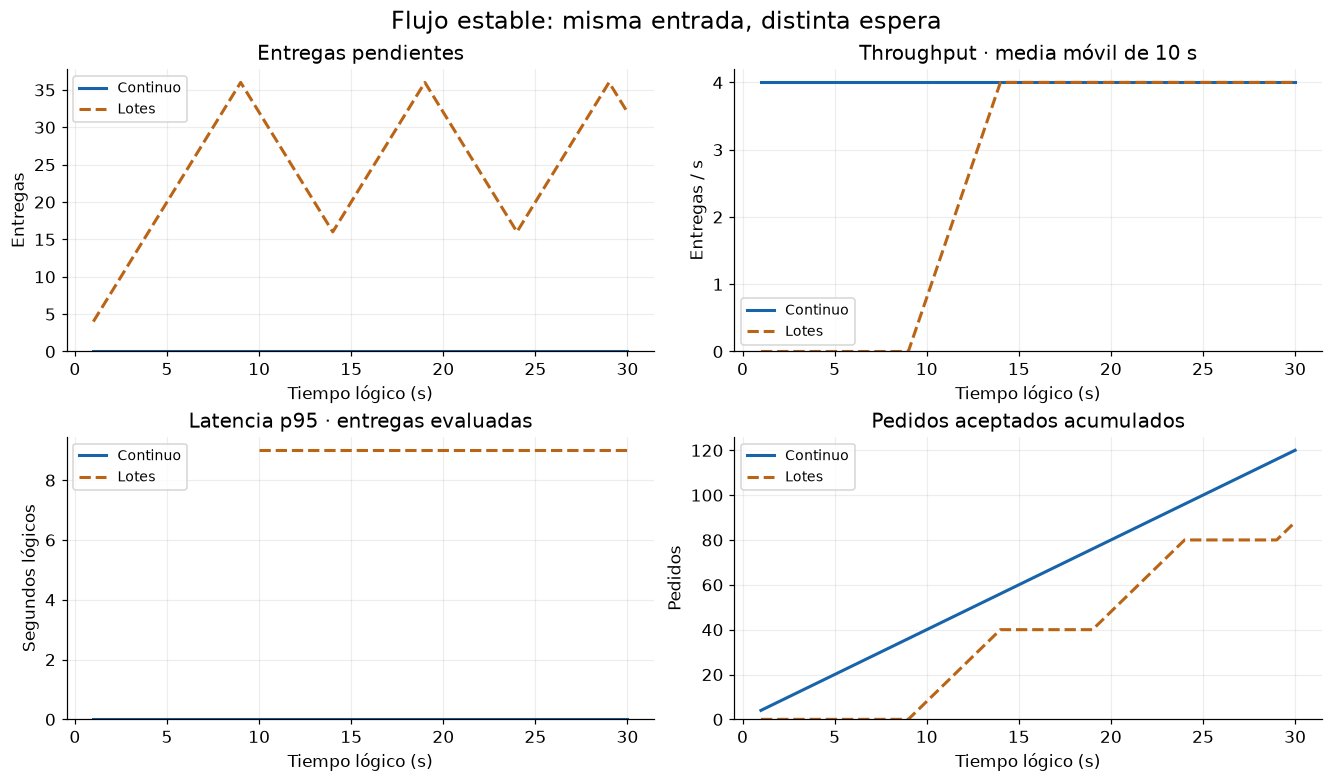

In [4]:
estable = ejecutar(segundos=30, rate=4, capacity=8, batch=10, window=10)
resumen(estable)
figuras['01_flujo_estable'] = evolucion(estable, 'Flujo estable: misma entrada, distinta espera')


**Lectura esperada en t=30:** continuo, 120 aceptados y cola 0; lotes, 88 aceptados y cola 32.
La p95 es 0 s y 9 s respectivamente. El continuo publica dentro del mismo tick; no es latencia física cero.
La cola por lotes tiene forma de dientes de sierra: acumula mientras espera y disminuye al procesar.
No confundas los 88 aceptados con pérdida de pedidos: faltan 32 por evaluar.

**Cerrar el origen no es detener el procesamiento.** Ahora generamos hasta t=30 y dejamos procesar hasta t=60.


consumidor,t,pendientes,evaluados,aceptados,duplicados,tardios,throughput,media,p95
continuo,60,0,120,120,0,0,0.00,0.00,0
lotes,60,0,120,120,0,0,0.00,6.50,9


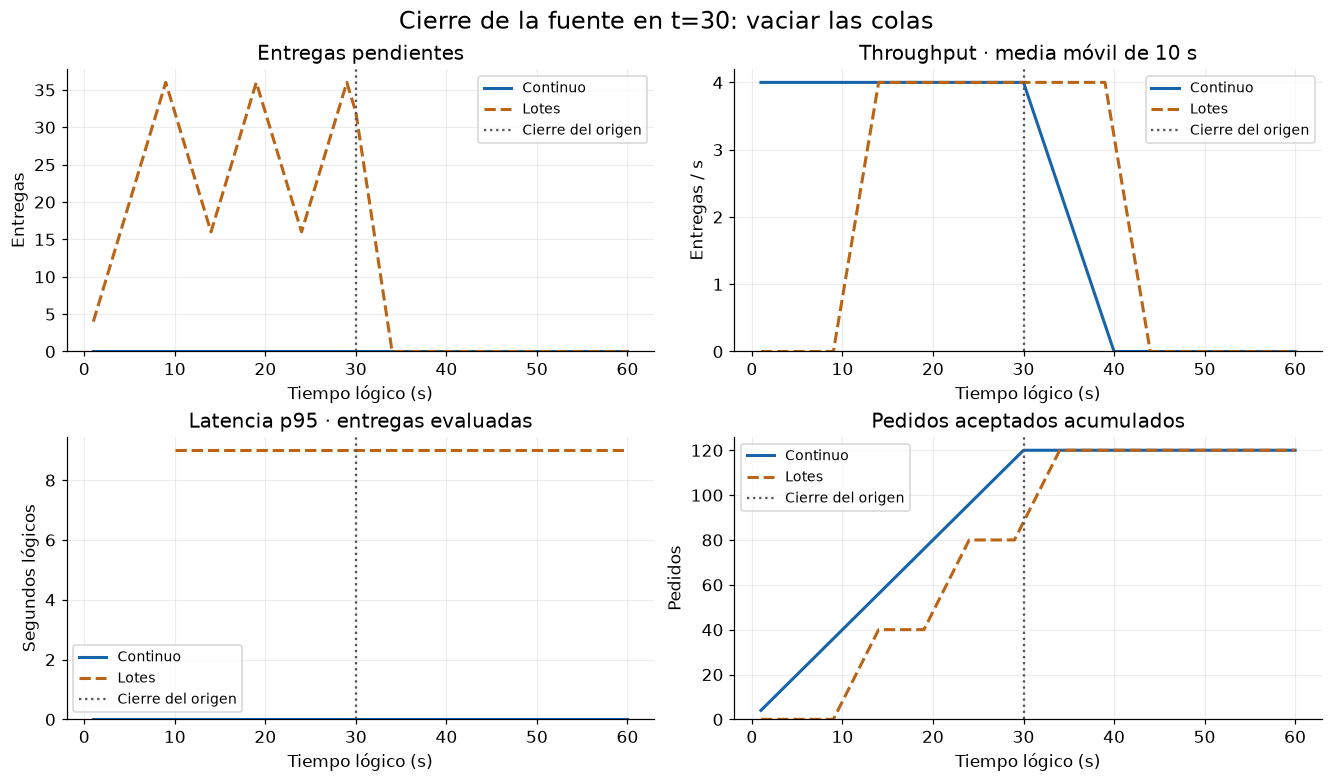

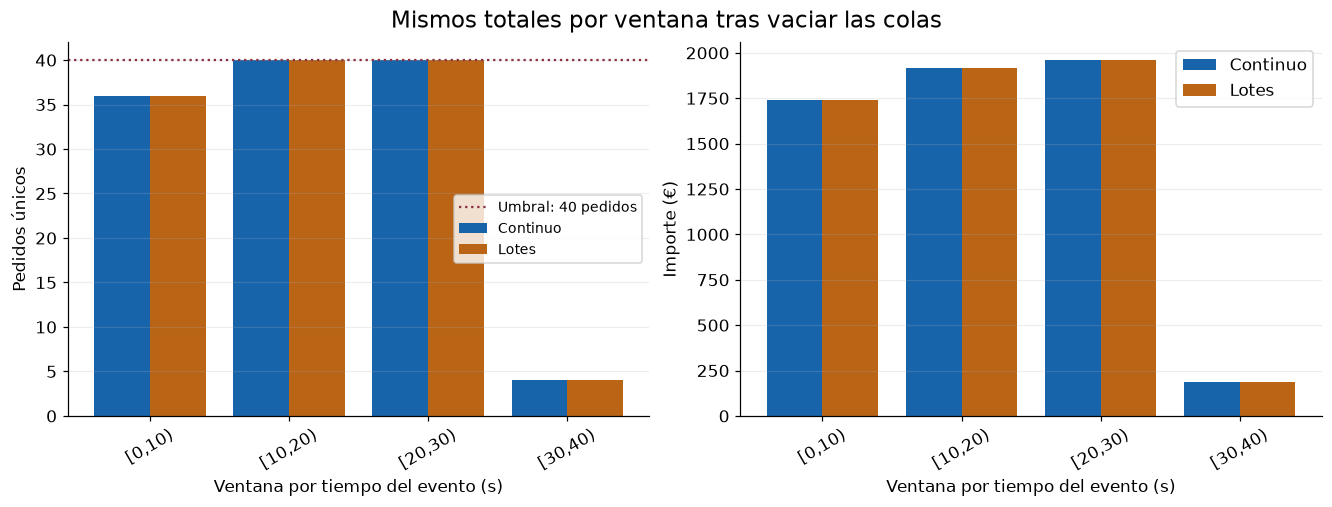

consumidor,inicio,fin,pedidos,centimos,estado
continuo,0,10,36,174000,Cerrada
continuo,10,20,40,191500,Cerrada
continuo,20,30,40,196000,Provisional
continuo,30,40,4,18500,Provisional
lotes,0,10,36,174000,Cerrada
lotes,10,20,40,191500,Cerrada
lotes,20,30,40,196000,Provisional
lotes,30,40,4,18500,Provisional


In [5]:
estable_cerrado = ejecutar(segundos=60, cierre=30)
resumen(estable_cerrado)
figuras['02_cierre_y_drenaje'] = evolucion(estable_cerrado, 'Cierre de la fuente en t=30: vaciar las colas', cierre=30)
figuras['03_ventanas'] = ventas_por_ventana(estable_cerrado, 'Mismos totales por ventana tras vaciar las colas')
tabla([dict(consumidor=p.modo, **w, estado='Cerrada' if w['fin']<=p.marca else 'Provisional')
       for p in estable_cerrado.consumidores for w in p.ventanas.values()])


**Interpretación:** ambos terminan con 120 pedidos aceptados. El throughput cae a cero cuando ya no hay trabajo.
La primera ventana [0,10) tiene 36 pedidos: la fuente comienza en t=1, no en t=0.
La ventana [30,40) recibe los cuatro pedidos de t=30 y puede seguir provisional después de cerrar el origen.
Los importes se suman en céntimos enteros y solo se convierten a euros para representarlos.


### 8 · Experimento 2: sobrecarga · 10 minutos

**Predice:** con entrada 12/s y capacidad 5/s, ¿cuánto habrá crecido la cola del continuo en 30 s?
Ejecuta y después compara con una capacidad de 20/s, manteniendo el resto igual.


Capacidad 5/s:


consumidor,t,pendientes,evaluados,aceptados,duplicados,tardios,throughput,media,p95
continuo,30,210,150,150,0,0,5.00,8.74,17
lotes,30,255,105,105,0,0,5.00,15.11,21


Capacidad 20/s:


consumidor,t,pendientes,evaluados,aceptados,duplicados,tardios,throughput,media,p95
continuo,30,0,360,360,0,0,12.00,0.00,0
lotes,30,100,260,260,0,0,12.00,7.12,9


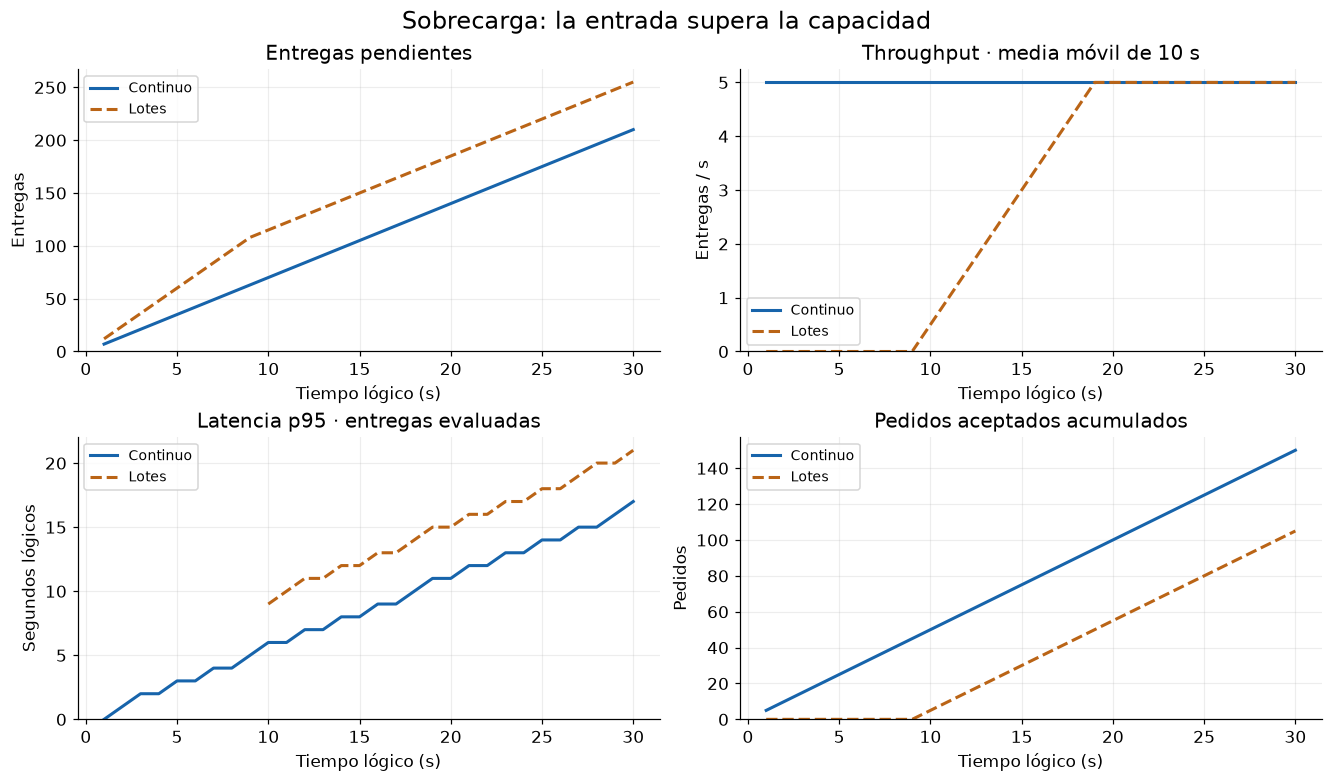

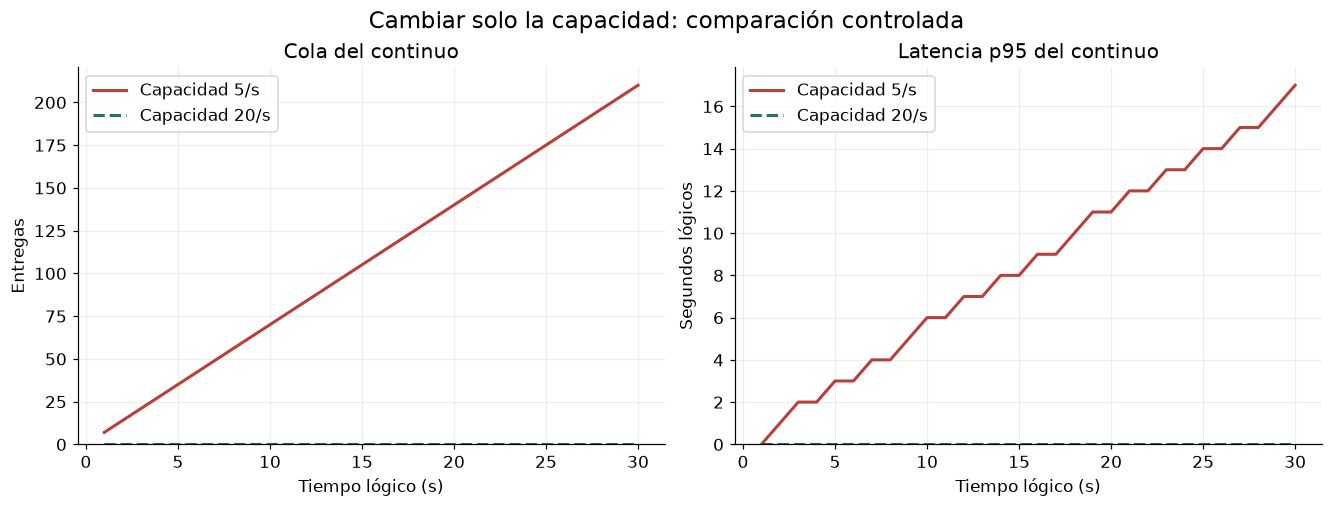

In [5]:
sobrecarga = ejecutar(segundos=30, rate=12, capacity=5)
ampliada = ejecutar(segundos=30, rate=12, capacity=20)
print('Capacidad 5/s:'); resumen(sobrecarga)
print('Capacidad 20/s:'); resumen(ampliada)
figuras['04_sobrecarga'] = evolucion(sobrecarga, 'Sobrecarga: la entrada supera la capacidad')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for s, color, estilo in [(sobrecarga, '#b6413a', '-'), (ampliada, '#237751', '--')]:
    filas = [r for r in s.historial if r['consumidor']=='continuo']
    for ax, campo in zip(axes, ['pendientes', 'p95']):
        ax.plot([r['t'] for r in filas], [r[campo] for r in filas], estilo,
                color=color, linewidth=2, label=f'Capacidad {s.config["capacity"]}/s')
for ax, titulo, unidad in zip(axes, ['Cola del continuo', 'Latencia p95 del continuo'], ['Entregas', 'Segundos lógicos']):
    ax.set(title=titulo, xlabel='Tiempo lógico (s)', ylabel=unidad); ax.set_ylim(bottom=0); ax.legend()
fig.suptitle('Cambiar solo la capacidad: comparación controlada', fontsize=15)
plt.show(); figuras['05_capacidad'] = fig


**Resultado esperado:** (12−5)×30 = **210** entregas pendientes en el continuo.
Con capacidad 20/s, su cola queda en cero. El consumidor por lotes aún puede tener cola por el calendario de ejecución.

**Explica:** ¿qué costaría aumentar capacidad? ¿Se podrían reducir eventos innecesarios o repartir carga?
En un sistema real también habría que controlar límites de cola, presión sobre el origen y recuperación ante fallos.


### 9 · Experimento 3: retrasos, duplicados y tolerancia · 12 minutos

Cada quinto pedido llega 15 s tarde. Cada décimo se retransmite, conservando `eventId`.
Generamos hasta t=30 y procesamos hasta t=60. Comparamos tolerancias de **5 s** y **20 s**.

**Predice:** ¿aumentarán las ventas por los duplicados? ¿Aumentar la tolerancia reduce la latencia o cambia qué se admite?


Tolerancia: 5 s


consumidor,t,pendientes,evaluados,aceptados,duplicados,tardios,throughput,media,p95
continuo,60,0,132,106,12,14,0.00,4.18,16
lotes,60,0,132,106,12,14,0.00,10.39,23


Tolerancia: 20 s


consumidor,t,pendientes,evaluados,aceptados,duplicados,tardios,throughput,media,p95
continuo,60,0,132,120,12,0,0.00,4.18,16
lotes,60,0,132,120,12,0,0.00,10.39,23


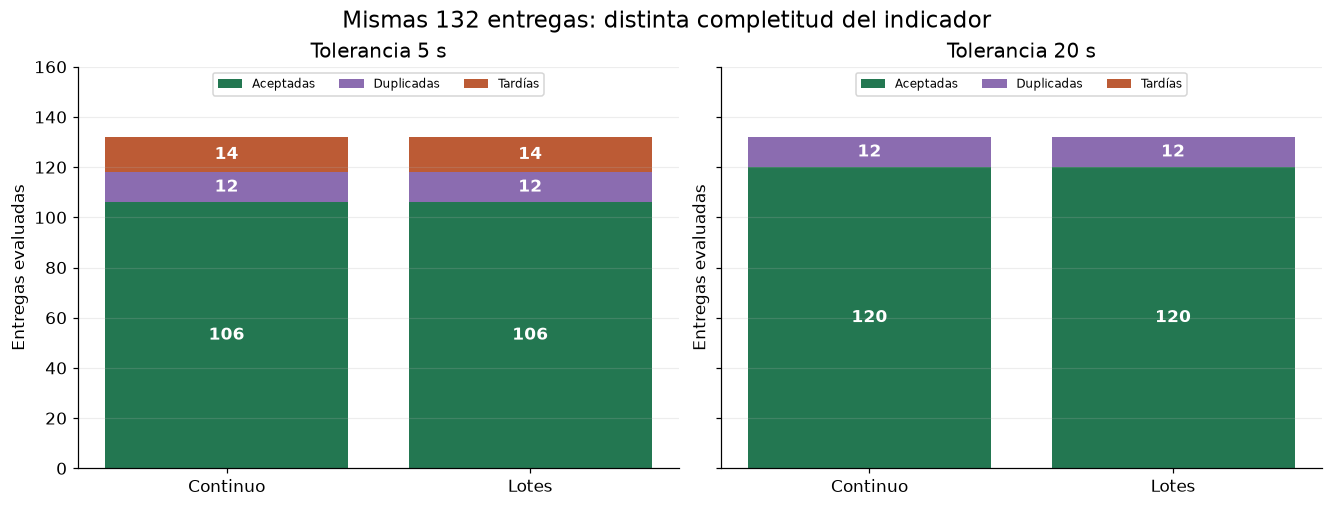

tolerancia,consumidor,eventId,eventTime,arrivalTime,processed,windowStart,status
5,continuo,E5,2,17,17,0,tardío
5,lotes,E5,2,17,22,0,tardío
20,continuo,E5,2,17,17,0,aceptado
20,lotes,E5,2,17,22,0,aceptado


In [6]:
retrasos5 = ejecutar(segundos=60, cierre=30, delay=15, duplicates=True, tolerance=5)
retrasos20 = ejecutar(segundos=60, cierre=30, delay=15, duplicates=True, tolerance=20)
for s in [retrasos5, retrasos20]:
    print('Tolerancia:', s.config['tolerance'], 's'); resumen(s)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True, sharey=True)
for ax, s in zip(axes, [retrasos5, retrasos20]):
    bases = [0, 0]
    for campo, etiqueta, color in [('aceptados', 'Aceptadas', '#237751'),
                                    ('duplicados', 'Duplicadas', '#8b6cb0'),
                                    ('tardios', 'Tardías', '#bc5b35')]:
        valores = [getattr(p, campo) for p in s.consumidores]
        ax.bar(['Continuo', 'Lotes'], valores, bottom=bases, label=etiqueta, color=color)
        for i, v in enumerate(valores):
            if v: ax.text(i, bases[i]+v/2, str(v), ha='center', va='center', color='white', fontweight='bold')
        bases = [b+v for b,v in zip(bases,valores)]
    ax.set(title=f'Tolerancia {s.config["tolerance"]} s', ylabel='Entregas evaluadas'); ax.grid(axis='x', visible=False)
    ax.set_ylim(0, 160); ax.legend(loc='upper center', ncol=3, fontsize=8)
fig.suptitle('Mismas 132 entregas: distinta completitud del indicador', fontsize=15)
plt.show(); figuras['06_tardios'] = fig

tabla([dict(tolerancia=s.config['tolerance'], consumidor=p.modo,
            **next(e for e in p.registro if e['eventId']=='E5'))
       for s in [retrasos5, retrasos20] for p in s.consumidores],
      ['tolerancia','consumidor','eventId','eventTime','arrivalTime','processed','windowStart','status'])


**Lectura esperada:** con tolerancia 5, cada consumidor acepta 106 pedidos, detecta 12 duplicados y aparta 14 tardíos.
Con tolerancia 20, acepta 120, detecta 12 duplicados y no aparta tardíos en esta ejecución.

E5 ocurre en t=2 y llega en t=17: pertenece a **[0,10)**. Cambiar la tolerancia no acelera su transporte.
Aumentarla hace que la ventana permanezca abierta más tiempo. El registro permite revisar lo apartado.

### 10 · La media no cuenta toda la historia

La distribución siguiente usa **todas las entregas evaluadas**, no solo las aceptadas.
Los eventos demorados y la espera de los lotes aparecen en las colas de la distribución.


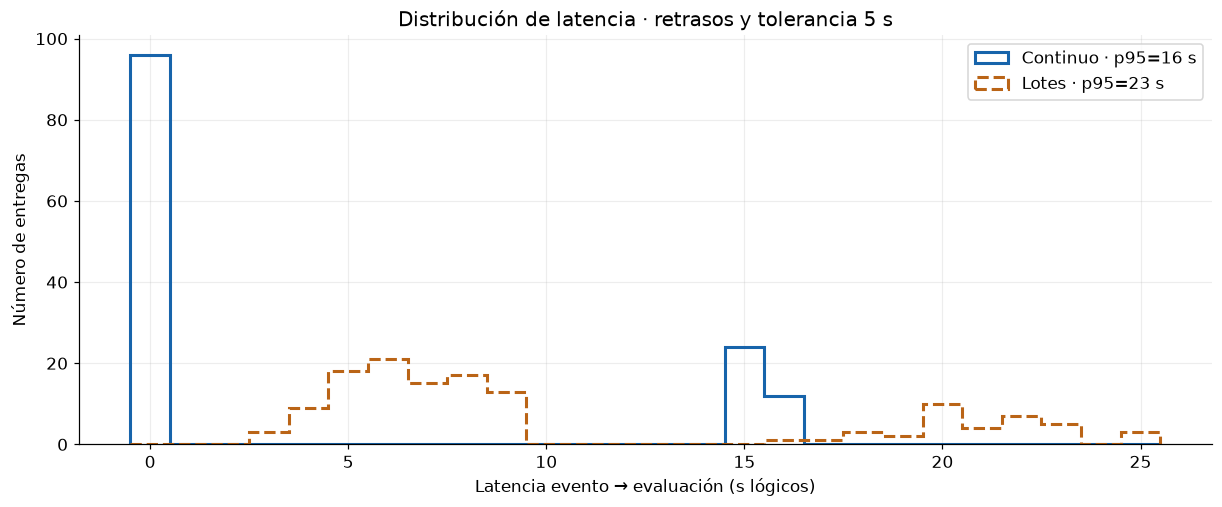

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
maximo = max(max(p.latencias) for p in retrasos5.consumidores)
bordes = [i-.5 for i in range(maximo+2)]
for p, estilo in [(retrasos5.continuo, '-'), (retrasos5.lotes, '--')]:
    ax.hist(p.latencias, bins=bordes, histtype='step', linewidth=2, linestyle=estilo,
            color=COLORES[p.modo], label=f'{p.modo.capitalize()} · p95={p.resumen()["p95"]} s')
ax.set(title='Distribución de latencia · retrasos y tolerancia 5 s',
       xlabel='Latencia evento → evaluación (s lógicos)', ylabel='Número de entregas')
ax.legend(); plt.show(); figuras['07_distribucion_latencia'] = fig


### 11 · Tu propio escenario

Cambia **un parámetro cada vez**. Antes de ejecutar, escribe qué esperas que cambie.
Los nombres de parámetros coinciden con el simulador HTML:

| Parámetro | Qué cambia |
|---|---|
| `rate` | Pedidos nuevos/s |
| `capacity` | Capacidad por consumidor/s |
| `batch` | Intervalo entre oportunidades de abrir un lote |
| `window` | Tamaño de ventana fija |
| `tolerance` | Retraso de la marca respecto al máximo evento observado |
| `delay` | Retraso de cada quinto pedido |
| `duplicates` | Retransmisión de cada décimo evento |

No compares el umbral de 40 pedidos como si significase lo mismo en ventanas de 5 s y de 30 s.


consumidor,t,pendientes,evaluados,aceptados,duplicados,tardios,throughput,media,p95
continuo,60,0,180,180,0,0,0.00,0.00,0
lotes,60,0,180,180,0,0,0.00,7.77,9


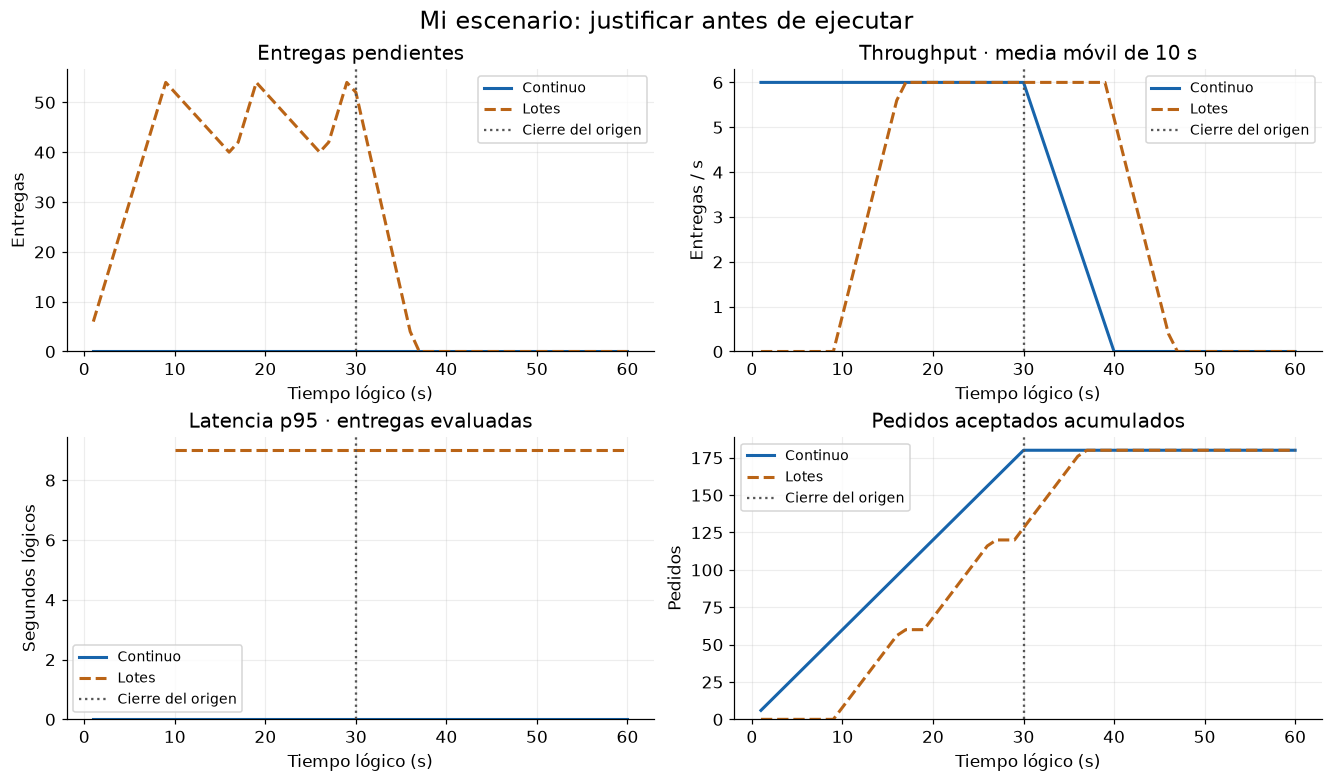

In [8]:
mis_parametros = dict(rate=6, capacity=8, batch=10, window=10,
                     tolerance=5, delay=0, duplicates=False)
mi_simulacion = ejecutar(segundos=60, cierre=30, **mis_parametros)
resumen(mi_simulacion)
figuras['08_mi_escenario'] = evolucion(mi_simulacion, 'Mi escenario: justificar antes de ejecutar', cierre=30)


### 12 · Demostración animada opcional

Esta celda está **desactivada por defecto** para que «Ejecutar todo» termine rápidamente.
Si cambias `ANIMAR = True`, verás cómo crecen las colas durante 20 pasos.
La pausa solo controla la reproducción visual; no cambia el cálculo de latencias.
Al terminar, la gráfica final queda visible. No requiere widgets ni extensiones.


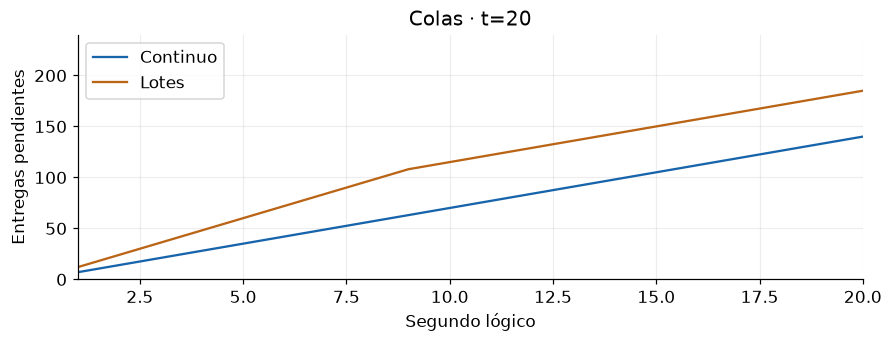

In [9]:
ANIMAR = True
if ANIMAR:
    import time
    demo = Simulacion(rate=12, capacity=5)
    for _ in range(20):
        demo.paso()
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(8, 3), constrained_layout=True)
        for p in demo.consumidores:
            filas = [r for r in demo.historial if r['consumidor']==p.modo]
            ax.plot([r['t'] for r in filas], [r['pendientes'] for r in filas],
                    color=COLORES[p.modo], label=p.modo.capitalize())
        ax.set(xlim=(1,20), ylim=(0,240), xlabel='Segundo lógico', ylabel='Entregas pendientes', title=f'Colas · t={demo.t}')
        ax.legend(); display(fig); plt.close(fig)
        time.sleep(.25)
else:
    print('Animación desactivada. Cambia ANIMAR a True para reproducirla.')


### 13 · Comprobar antes de sacar conclusiones

En cada consumidor: **recibidas = pendientes + aceptadas + duplicadas + tardías**.
Las entregas en tránsito no han llegado todavía. El motor comprueba esta igualdad en cada paso.
Las siguientes comprobaciones verifican resultados de referencia del simulador original.


In [10]:
assert estable.continuo.aceptados == 120 and estable.lotes.aceptados == 88
assert estable.lotes.pendientes == 32
assert sobrecarga.continuo.pendientes == 210
assert ampliada.continuo.pendientes == 0
assert estable_cerrado.continuo.ventanas == estable_cerrado.lotes.ventanas
for p in retrasos5.consumidores:
    assert (p.aceptados, p.duplicados, p.tardios) == (106, 12, 14)
for p in retrasos20.consumidores:
    assert (p.aceptados, p.duplicados, p.tardios) == (120, 12, 0)
for s in [estable, estable_cerrado, sobrecarga, ampliada, retrasos5, retrasos20, mi_simulacion]:
    for p in s.consumidores:
        assert s.recibidos == p.pendientes+p.aceptados+p.duplicados+p.tardios
        assert sum(w['pedidos'] for w in p.ventanas.values()) == p.aceptados
print('Correcto: resultados de referencia, ventanas y conservación de entregas.')


NameError: name 'estable_cerrado' is not defined

### 14 · Exportar evidencias (opcional)

Cambia `EXPORTAR` a `True` para crear una **carpeta nueva con fecha y hora** en el directorio de trabajo.
Incluye las figuras PNG, parámetros JSON, series temporales CSV y entregas evaluadas, pendientes y en tránsito.
No sobrescribe una carpeta existente. No es necesario para consultar el cuaderno.
En Colab podrás descargar la carpeta desde el explorador de archivos o comprimirla con sus herramientas.


In [11]:
EXPORTAR = False
if EXPORTAR:
    from datetime import datetime
    destino = Path('resultados_s05_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
    destino.mkdir(exist_ok=False)
    escenarios = dict(estable=estable, estable_cerrado=estable_cerrado,
                      sobrecarga=sobrecarga, ampliada=ampliada,
                      retrasos5=retrasos5, retrasos20=retrasos20, mi_escenario=mi_simulacion)
    def guardar_csv(nombre, filas):
        columnas = list(dict.fromkeys(k for fila in filas for k in fila))
        with (destino/nombre).open('w', encoding='utf-8-sig', newline='') as f:
            escritor = csv.DictWriter(f, fieldnames=columnas, delimiter=';')
            escritor.writeheader(); escritor.writerows(filas)
    for nombre, s in escenarios.items():
        guardar_csv(nombre+'_metricas.csv', s.historial)
        entregas = [dict(tipo='evaluada', consumidor=p.modo, **e) for p in s.consumidores for e in p.registro]
        entregas += [dict(tipo='pendiente', consumidor=p.modo, **e) for p in s.consumidores for e in [*p.lote,*p.cola]]
        entregas += [dict(tipo='en_transito', consumidor='ambos', **e) for e in s.en_transito]
        guardar_csv(nombre+'_entregas.csv', entregas)
    (destino/'parametros.json').write_text(json.dumps({n:dict(config=s.config, t=s.t, produciendo=s.produciendo) for n,s in escenarios.items()}, indent=2), encoding='utf-8')
    for nombre, fig in figuras.items():
        fig.savefig(destino/(nombre+'.png'), dpi=160, bbox_inches='tight')
    print('Evidencias guardadas en:', destino.resolve())
else:
    print('Exportación desactivada; no se han creado archivos.')


Exportación desactivada; no se han creado archivos.


### 15 · Diseño final y entrega · 15 minutos

Elabora una página con:
1. Decisión empresarial y objetivo de frescura (por ejemplo, p95 ≤ 5 s, acompañado de cola y completitud).
2. Modelo: grano, campos, claves y relaciones.
3. Arquitectura: **origen → canal → validación y deduplicación → agregación → indicador/señal**.
4. Política de ventanas, duplicados y tardíos; ruta histórica para conciliar los datos apartados.
5. Dos gráficas de ejecuciones comparables y una explicación de lo que demuestran.

**Rúbrica / 10:** problema y modelo (3); diseño (2); experimentación con evidencias (3); interpretación y límites (2).
Para cada criterio: completo si está bien justificado, mitad si es parcial y cero si falta o contradice la evidencia.

### Preguntas de salida
- ¿Qué diferencia hay entre pedido, evento y entrega?
- ¿Puede haber throughput alto y latencia alta a la vez?
- ¿En qué ventana cae t=20 con ventanas de 10 s?
- ¿Por qué más tolerancia no significa transporte más rápido?
- ¿Cuándo elegirías batch y cuándo procesamiento próximo al tiempo real?

<details><summary>Respuestas orientativas</summary>
Un pedido es el objeto de negocio; un evento es un hecho sobre él; una entrega es una recepción técnica del evento.
Sí: puede haber mucho procesamiento mientras se resuelve una cola antigua.
t=20 cae en [20,30). La tolerancia cambia el cierre y la admisión, no el transporte.
Batch puede servir para cierres y conciliación; el procesamiento próximo al tiempo real sirve para decisiones que pierden valor si se retrasan.
</details>

### Límites de la solución

Es un modelo local en memoria: no implementa un broker real, persistencia, recuperación ni fallos distribuidos.
Conserva todas las ventanas, IDs y registros durante la ejecución; **no es una estrategia de memoria acotada**.
Las capacidades son parámetros, no benchmarks. Se simulan datos válidos y una confirmación por pedido.
La deduplicación didáctica no constituye una garantía de entrega «exactly once» en producción.

### Fuentes y continuidad

- [Apache Beam: ventanas](https://beam.apache.org/documentation/programming-guide/#windowing).
- [Apache Beam: marcas de agua y tardíos](https://beam.apache.org/documentation/programming-guide/#watermarks-and-late-data).
- [Apache Spark: Structured Streaming](https://spark.apache.org/docs/latest/streaming/index.html).

Continuidad con la tienda Conecta de la sesión 4 y el simulador HTML de la sesión 5.
Las fuentes conceptuales se consultaron al preparar la sesión el 5 de noviembre de 2026.
